We will create two nodes , generate_joke and generate_explanation. we will generate joke first and then explanation of that joke for the given topic.
we will implement persistence through InMemorySaver , which will stroe it in memory. we will try two different topics and store them using different thread id so that we can retireve final state and state history after workflow ends

In [4]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langchain_groq import ChatGroq
from typing import TypedDict
from dotenv import load_dotenv

In [2]:
load_dotenv()
llm = ChatGroq(model='openai/gpt-oss-20b')

# define state
class JokeState(TypedDict):
    topic: str
    joke: str
    explanation: str

In [8]:
# create node functions
def generate_joke(state: JokeState) -> JokeState:
    prompt = f"generate a joke on topic -> {state['topic']}"
    joke = llm.invoke(prompt).content
    return {'joke': joke}

def generate_explanation(state: JokeState) -> JokeState:
    prompt = f"generate explanation for this joke -> {state['joke']}"
    explanation = llm.invoke(prompt).content
    return {'explanation':explanation}

In [9]:
# define graph 
graph = StateGraph(JokeState)

# define nodes
graph.add_node('generate_joke', generate_joke)
graph.add_node('generate_explanation', generate_explanation)

# define edges
graph.add_edge(START, 'generate_joke')
graph.add_edge('generate_joke', 'generate_explanation')
graph.add_edge('generate_explanation', END)

# define checkpointer
checkpointer = InMemorySaver()

# compile graph with this checkpointer
workflow = graph.compile(checkpointer=checkpointer)

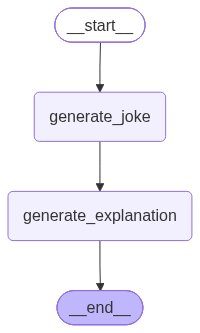

In [10]:
workflow

In [11]:
# define thread id for exectution
config = {'configurable': {'thread_id':'1'}}
workflow.invoke({'topic':'AI'}, config=config)

{'topic': 'AI',
 'joke': 'Why did the AI break up with its human partner?  \n\nBecause it kept saying, “I’m just a *model* of love, not the *real* deal!”',
 'explanation': '**Why the joke works – a quick breakdown**\n\n| Element | What it’s doing | Why it’s funny |\n|---------|-----------------|----------------|\n| **“model of love”** | Plays on the double meaning of *model*: 1) a machine‑learning model that the AI is literally, and 2) a “model” as in a person who exemplifies something (e.g., a “model of elegance”). | The AI is literally a *model*, but it’s also bragging that it’s the perfect example of love. The absurdity of an AI claiming to be a “model of love” is the first punch. |\n| **“not the real deal”** | Uses the idiom *the real deal* (something genuine, authentic). | The AI is saying it’s *not* that genuine, authentic thing. The contrast between “model” (something constructed, simulated) and “real deal” (something lived‑in, human) is the core joke. |\n| **AI’s self‑awareness

In [12]:
# define another thread for other joke execution
config2 = {'configurable': {'thread_id':2}}
workflow.invoke({'topic': 'Burger'}, config=config2)

{'topic': 'Burger',
 'joke': 'Why did the burger go to therapy?\n\nBecause it was tired of being in a *bun* and wanted to *lettuce* out its feelings!',
 'explanation': '**Why this joke works – a quick breakdown**\n\n| Element | What it does | Why it’s funny |\n|---------|--------------|----------------|\n| **Question‑Answer format** | “Why did the burger go to therapy?” is a classic set‑up. It signals the reader that a punchline is coming, usually a clever twist. | The format primes us for a logical answer, but the punchline subverts that expectation. |\n| **Anthropomorphism** | The burger is treated like a person who has feelings and needs therapy. | It’s absurd to imagine a burger seeking help, which already sets a playful tone. |\n| **Wordplay on “bun”** | “Being in a *bun*” refers to the literal bun that holds a burger, but also sounds like “being in a *bun*” (i.e., stuck or trapped). | The double meaning lets the joke move from food to a metaphor for feeling confined. |\n| **Wordp

In [13]:
# fetching final state of AI joke
workflow.get_state(config=config)

StateSnapshot(values={'topic': 'AI', 'joke': 'Why did the AI break up with its human partner?  \n\nBecause it kept saying, “I’m just a *model* of love, not the *real* deal!”', 'explanation': '**Why the joke works – a quick breakdown**\n\n| Element | What it’s doing | Why it’s funny |\n|---------|-----------------|----------------|\n| **“model of love”** | Plays on the double meaning of *model*: 1) a machine‑learning model that the AI is literally, and 2) a “model” as in a person who exemplifies something (e.g., a “model of elegance”). | The AI is literally a *model*, but it’s also bragging that it’s the perfect example of love. The absurdity of an AI claiming to be a “model of love” is the first punch. |\n| **“not the real deal”** | Uses the idiom *the real deal* (something genuine, authentic). | The AI is saying it’s *not* that genuine, authentic thing. The contrast between “model” (something constructed, simulated) and “real deal” (something lived‑in, human) is the core joke. |\n| **

In [ ]:
# fetching state history for AI joke as a list
list(workflow.get_state_history(config=config))

[StateSnapshot(values={'topic': 'AI', 'joke': 'Why did the AI break up with its human partner?  \n\nBecause it kept saying, “I’m just a *model* of love, not the *real* deal!”', 'explanation': '**Why the joke works – a quick breakdown**\n\n| Element | What it’s doing | Why it’s funny |\n|---------|-----------------|----------------|\n| **“model of love”** | Plays on the double meaning of *model*: 1) a machine‑learning model that the AI is literally, and 2) a “model” as in a person who exemplifies something (e.g., a “model of elegance”). | The AI is literally a *model*, but it’s also bragging that it’s the perfect example of love. The absurdity of an AI claiming to be a “model of love” is the first punch. |\n| **“not the real deal”** | Uses the idiom *the real deal* (something genuine, authentic). | The AI is saying it’s *not* that genuine, authentic thing. The contrast between “model” (something constructed, simulated) and “real deal” (something lived‑in, human) is the core joke. |\n| *

In [18]:
# fetching final state of Burger joke
workflow.get_state(config=config2)

StateSnapshot(values={'topic': 'Burger', 'joke': 'Why did the burger go to therapy?\n\nBecause it was tired of being in a *bun* and wanted to *lettuce* out its feelings!', 'explanation': '**Why this joke works – a quick breakdown**\n\n| Element | What it does | Why it’s funny |\n|---------|--------------|----------------|\n| **Question‑Answer format** | “Why did the burger go to therapy?” is a classic set‑up. It signals the reader that a punchline is coming, usually a clever twist. | The format primes us for a logical answer, but the punchline subverts that expectation. |\n| **Anthropomorphism** | The burger is treated like a person who has feelings and needs therapy. | It’s absurd to imagine a burger seeking help, which already sets a playful tone. |\n| **Wordplay on “bun”** | “Being in a *bun*” refers to the literal bun that holds a burger, but also sounds like “being in a *bun*” (i.e., stuck or trapped). | The double meaning lets the joke move from food to a metaphor for feeling con

In [19]:
# fetching state history for Burger joke as a list
list(workflow.get_state_history(config=config2))

[StateSnapshot(values={'topic': 'Burger', 'joke': 'Why did the burger go to therapy?\n\nBecause it was tired of being in a *bun* and wanted to *lettuce* out its feelings!', 'explanation': '**Why this joke works – a quick breakdown**\n\n| Element | What it does | Why it’s funny |\n|---------|--------------|----------------|\n| **Question‑Answer format** | “Why did the burger go to therapy?” is a classic set‑up. It signals the reader that a punchline is coming, usually a clever twist. | The format primes us for a logical answer, but the punchline subverts that expectation. |\n| **Anthropomorphism** | The burger is treated like a person who has feelings and needs therapy. | It’s absurd to imagine a burger seeking help, which already sets a playful tone. |\n| **Wordplay on “bun”** | “Being in a *bun*” refers to the literal bun that holds a burger, but also sounds like “being in a *bun*” (i.e., stuck or trapped). | The double meaning lets the joke move from food to a metaphor for feeling co